<center><h2> Spatial redistribution of a globally constant marine biological carbon pump </h2></center>
    
<center><h3> Figures and statistics </h3></center>

**L. Delaigue<sup>1, 2</sup>\, R. Sauzède<sup>3</sup>, O. Sulpis<sup>4</sup>, P. W. Boyd<sup>5</sup>, H. Claustre<sup>2</sup>, G-J Reichart<sup>1, 6</sup> and M. P. Humphreys<sup>1</sup>**

<sup>1</sup>Department of Ocean Systems (OCS), NIOZ Royal Netherlands Institute for Sea Research, PO Box 59, 1790 AB Den Burg (Texel), the Netherlands

<sup>2</sup>Sorbonne Université, CNRS, Laboratoire d’Océanographie de Villefranche, Villefranche-Sur-Mer, France

<sup>3</sup>Sorbonne Université, CNRS, Institut de la Mer de Villefranche, Villefranche-Sur-Mer, France

<sup>4</sup>CEREGE, Aix Marseille Univ, CNRS, IRD, INRAE, Collège de France, Aix-en-Provence, France

<sup>5</sup>Institute for Marine and Antarctic Studies, University of Tasmania, Hobart, Tasmania, Australia

<sup>6</sup>Department of Earth Sciences, Utrecht University, Utrecht, the Netherlands

## Abstract

Marine dissolved inorganic carbon (DIC) is a key component of the global ocean carbon cycle. Over recent decades, DIC has increased due to rising anthropogenic CO<sub>2</sub>, but the component of DIC change due to the biological carbon pump (BCP), which transfers carbon from the surface to the deep ocean, remains highly uncertain. Using the GOBAI-O<sub>2</sub> data product and the CANYON-B and CONTENT algorithms, we reconstructed the 3-dimensional global DIC<sub>total</sub> distribution from 2004 to 2022 and decomposed it into DIC<sub>soft</sub> (resulting from organic matter degradation), DIC<sub>carb</sub> (resulting from carbonate dissolution), and DIC<sub>anth</sub> (anthropogenic CO<sub>2</sub> plus changes in air-sea disequilibrium). We found a significant DIC<sub>total</sub> change throughout the water column, with surface concentrations increasing by ~1.0 ± 0.23 μmol kg<sup>-1</sup> yr<sup>-1</sup>, driven by DIC<sub>anth</sub> (>90% contribution). Despite a globally constant signal in DIC<sub>soft</sub>, substantial regional trends emerged. Changes in circulation, particle sinking, and remineralization altered the vertical and horizontal distributions of DIC<sub>soft</sub>. In some regions, DIC<sub>soft</sub> accumulated at shallower depths, shortening residence times; in others, it was transported deeper, enhancing long-term storage. Although these widespread and divergent trends had little net effect on the global DIC<sub>soft</sub> inventory from 2004-2022, the emerging spatial reorganization of the BCP may signal an evolving instability in the ocean carbon sink under continued climate forcing.

**____________________________________________________________________________________________________________________________**


## TEST FULL PIPELINE

In [79]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import xarray as xr
import gsw
import koolstof as ks
import matplotlib.dates as mdates

print("Starting script...")

# =============================================================================
# 1 - Define Paths
# =============================================================================
CONTENT_DATA_PATH = "data/"
OUT_PATH = "data/NEW_DIC_band_integrated_change_map_monte_carlo_online_pres_diff.nc"

print("Loading dataset...")
ds = xr.open_dataset(os.path.join(CONTENT_DATA_PATH, "CONTENT_DIC_v2-1.nc"))
print("Dataset loaded.")

# =============================================================================
# 2 - Compute needed variables (same as you did)
# =============================================================================
print("Calculating absolute salinity and potential temperature...")
ds["salinity_absolute"] = gsw.conversions.SA_from_SP(ds["sal"], ds["pres"], ds["lon"], ds["lat"])
ds["theta"] = gsw.conversions.pt0_from_t(ds["salinity_absolute"], ds["temp"], ds["pres"])
ds["aou"] = ks.parameterisations.aou_GG92(
    oxygen=ds["oxy"], temperature=ds["theta"], salinity=ds["sal"]
)[0]
print("Salinity and temperature calculations complete.")

# Rename (fixing your missing brace + keep only what you use)
ds = ds.rename({
    "aou": "AOU",
    "uncer": "AOU_uncertainty",
})
ds = ds[["AOU", "AOU_uncertainty"]]

# =============================================================================
# 3 - Convert time to matplotlib numeric days (EXACTLY like your first script)
# =============================================================================
print("Converting time to numeric format (matplotlib days)...")
ds = ds.assign_coords(time=("time", mdates.date2num(ds["time"].values)))
print("Time conversion complete.")

# =============================================================================
# 4 - Monte Carlo + band integration using your exact pipeline
# =============================================================================
num_iterations = 2
print(f"Running Monte Carlo with {num_iterations} iterations...")

# Constants (same as you had)
sp_constant_aou_mean = 117 / -170
sigma_sp = 0.092

rng = np.random.default_rng()

# --- Band-aware version of your function ---
def compute_slope_integrated_band(ds_in, var, pmin=None, pmax=None):
    """
    EXACT SAME PIPELINE AS YOUR FIRST FIGURE, but optionally limited to a pressure band.

    Steps:
      - polyfit over time (time is matplotlib days)
      - convert slope to per-year (*365.25)
      - multiply by pres.diff('pres') (dbar)
      - sum over pres (or pres subset)
    """
    da = ds_in[var]

    # Optional band selection
    if (pmin is not None) and (pmax is not None):
        da = da.sel(pres=slice(pmin, pmax))

        # IMPORTANT: also restrict pressure coord used for diff to the same band
        pres_band = da["pres"]
    else:
        pres_band = ds_in["pres"]

    # linear trend over time (per day) -> per year
    polyfit = da.polyfit(dim="time", deg=1, skipna=True)
    slope = polyfit.polyfit_coefficients.sel(degree=1) * 365.25  # per year

    # layer thickness (same approach you used)
    layer_thickness = pres_band.diff("pres").fillna(0)

    # broadcast thickness to slope shape
    layer_thickness = layer_thickness.broadcast_like(slope)

    # integrate over depth
    integrated_change = (slope * layer_thickness).sum(dim="pres", skipna=True)
    return integrated_change


# We'll compute 3 bands (edit if you only want the two)
bands = [
    (0, 200),
    (200, 1000),
    (1000, 1975),
]

# online mean/variance storage per output variable
mean_ds = xr.Dataset()
var_ds = xr.Dataset()

for i in range(1, num_iterations + 1):
    print(i)

    mc = ds.copy(deep=True)
    mc["AOU"] = mc["AOU"] + rng.normal(0, mc["AOU_uncertainty"])

    sp_constant_aou = rng.normal(sp_constant_aou_mean, sigma_sp)

    out_vars = {}

    # Compute AOU_rate and soft_pump change for each band
    for (pmin, pmax) in bands:
        aou_rate_band = compute_slope_integrated_band(mc, "AOU", pmin=pmin, pmax=pmax)

        soft_change_band = -sp_constant_aou * aou_rate_band

        tag = f"{int(pmin)}_{int(pmax)}"
        out_vars[f"AOU_rate_{tag}"] = aou_rate_band
        out_vars[f"soft_pump_aou_change_{tag}"] = soft_change_band

    iteration_ds = xr.Dataset(out_vars)

    # online mean/variance update
    if i == 1:
        mean_ds = iteration_ds
        var_ds = iteration_ds * 0
    else:
        delta = iteration_ds - mean_ds
        new_mean = mean_ds + delta / i
        var_ds = ((i - 1) * var_ds + delta * (iteration_ds - new_mean)) / i
        mean_ds = new_mean

# std dev
std_ds = np.sqrt(var_ds)

# attach uncertainties
for v in std_ds.data_vars:
    mean_ds[f"{v}_uncertainty"] = std_ds[v]

# match your unit conversion (if your AOU_rate here is in mmol/m^2/yr)
mean_ds = mean_ds / 1000.0

print(f"Saving: {OUT_PATH}")
mean_ds.to_netcdf(OUT_PATH)
print("Done.")


Starting script...
Loading dataset...
ERROR! Session/line number was not unique in database. History logging moved to new session 120
Dataset loaded.
Calculating absolute salinity and potential temperature...
Salinity and temperature calculations complete.
Converting time to numeric format (matplotlib days)...
Time conversion complete.
Running Monte Carlo with 2 iterations...
1
2
Saving: data/NEW_DIC_band_integrated_change_map_monte_carlo_online_pres_diff.nc
Done.


In [93]:
mean_ds

<xarray.Dataset> Size: 5MB
Dimensions:                                     (lat: 145, lon: 360)
Coordinates:
    degree                                      int64 8B 1
  * lat                                         (lat) float32 580B -64.5 ... ...
  * lon                                         (lon) float32 1kB -179.5 ... ...
Data variables:
    AOU_rate_0_200                              (lat, lon) float64 418kB -0.0...
    soft_pump_aou_change_0_200                  (lat, lon) float64 418kB -0.0...
    AOU_rate_200_1000                           (lat, lon) float64 418kB 0.29...
    soft_pump_aou_change_200_1000               (lat, lon) float64 418kB 0.18...
    AOU_rate_1000_1975                          (lat, lon) float64 418kB 0.23...
    soft_pump_aou_change_1000_1975              (lat, lon) float64 418kB 0.14...
    AOU_rate_0_200_uncertainty                  (lat, lon) float64 418kB 0.00...
    soft_pump_aou_change_0_200_uncertainty      (lat, lon) float64 418kB 0.00...
    AOU_rate_200_1000_uncertainty               (lat, lon) float64 418kB 0.00...
    soft_pump_aou_change_200_1000_uncertainty   (lat, lon) float64 418kB 0.02...
    AOU_rate_1000_1975_uncertainty              (lat, lon) float64 418kB 0.01...
    soft_pump_aou_change_1000_1975_uncertainty  (lat, lon) float64 418kB 0.02...

In [97]:
ds.soft_pump_aou_change_200_1000.min()

<xarray.DataArray 'soft_pump_aou_change_200_1000' ()> Size: 8B
array(-1.0927094)
Coordinates:
    degree   int64 8B ...

In [83]:
# ============================================================
# SCRIPT 2: add_N2_and_OCIM_then_merge_with_MC.py
#
# Inputs:
#   - CONTENT (for N² trend): data/CONTENT_DIC_v2-1.nc
#   - OCIM ideal age:        data/115838.nc
#   - MC band results:       data/NEW_DIC_band_integrated_change_map_monte_carlo_online_pres_diff.nc
#
# Output:
#   - merged dataset on the MC grid:
#       data/physics_proxies_merged_with_MC.nc
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import xarray as xr
import gsw

# ----------------------------
# Paths
# ----------------------------
CONTENT_PATH = "data/CONTENT_DIC_v2-1.nc"
OCIM_PATH    = "data/115838.nc"
MC_PATH      = "data/NEW_DIC_band_integrated_change_map_monte_carlo_online_pres_diff.nc"

OUT_MERGED   = "data/physics_proxies_merged_with_MC.nc"

# ----------------------------
# Load MC output (defines target grid)
# ----------------------------
print("Loading MC band-integrated dataset (target grid)...")
mc = xr.open_dataset(MC_PATH)

# Target grid
lat_t = mc["lat"]
lon_t = mc["lon"]

# ----------------------------
# 1) N² trend over 0–200 m (same method you had)
# ----------------------------
print("Loading CONTENT dataset for N²...")
dsC = xr.open_dataset(CONTENT_PATH)

def n2_mean_0_200_profile(sp, t, p, lon, lat):
    if np.all(np.isnan(sp)) or np.all(np.isnan(t)):
        return np.nan

    SA = gsw.SA_from_SP(sp, p, lon, lat)
    CT = gsw.CT_from_t(SA, t, p)

    N2, p_mid = gsw.Nsquared(SA, CT, p, lat)  # N2 at midpoints
    dp = np.diff(p)

    mask = np.isfinite(N2) & np.isfinite(dp) & (p_mid <= 200.0)
    if np.sum(mask) == 0:
        return np.nan

    return np.nansum(N2[mask] * dp[mask]) / np.nansum(dp[mask])

print("Computing N² mean (0–200 m) per profile...")
temp = dsC["temp"].transpose("time", "pres", "lat", "lon")
sal  = dsC["sal"].transpose("time", "pres", "lat", "lon")
presC = dsC["pres"]
lonC  = dsC["lon"]
latC  = dsC["lat"]

N2bar_0_200 = xr.apply_ufunc(
    n2_mean_0_200_profile,
    sal, temp, presC, lonC, latC,
    input_core_dims=[["pres"], ["pres"], ["pres"], [], []],
    output_core_dims=[[]],
    vectorize=True,
    dask="allowed",
    output_dtypes=[np.float64],
).rename("N2bar_0_200")

print("Computing annual mean and linear trend of N²...")
N2_annual = N2bar_0_200.groupby("time.year").mean("time", skipna=True)
fitN2 = N2_annual.polyfit(dim="year", deg=1, skipna=True)
trend_N2 = fitN2["polyfit_coefficients"].sel(degree=1).rename("trend_N2bar_0_200_peryr")

# Regrid N² trend to MC grid
print("Regridding N² trend to MC grid (nearest)...")
trend_N2_on_mc = trend_N2.interp(lat=lat_t, lon=lon_t, method="nearest")

# ----------------------------
# 2) OCIM ideal age band means + regrid to MC grid
# ----------------------------
print("Loading OCIM dataset for ideal age...")
dsO = xr.open_dataset(OCIM_PATH)

age = dsO["ideal_age"].rename({"Longitude": "lon360", "Latitude": "lat", "Depth": "Depth"})
age = age.assign_coords(
    lon360=("lon360", dsO["xt"].values),
    lat=("lat", dsO["yt"].values),
    Depth=("Depth", dsO["zt"].values),
)

# lon 0–360 -> -180–180
lon180 = ((age["lon360"] + 180) % 360) - 180
age = (
    age.assign_coords(lon=lon180)
       .swap_dims({"lon360": "lon"})
       .drop_vars("lon360")
       .sortby("lon")
)

dz = age["Depth"].diff("Depth")
dz3 = dz.broadcast_like(age.isel(Depth=slice(1, None)))

def ideal_age_mean_band(age_da, dz3, zmin, zmax):
    band = age_da.sel(Depth=slice(zmin, zmax))
    band_mid = band.isel(Depth=slice(1, None))
    w_mid = dz3.sel(Depth=band_mid["Depth"])
    return (band_mid * w_mid).sum("Depth", skipna=True) / w_mid.sum("Depth")

print("Computing ideal age band means...")
age_mean_0_200     = ideal_age_mean_band(age, dz3, 0, 200).rename("ideal_age_mean_0_200")
age_mean_200_1000  = ideal_age_mean_band(age, dz3, 200, 1000).rename("ideal_age_mean_200_1000")
age_mean_1000_2000 = ideal_age_mean_band(age, dz3, 1000, 2000).rename("ideal_age_mean_1000_2000")

print("Regridding ideal age means to MC grid (nearest)...")
age0_on_mc = age_mean_0_200.interp(lat=lat_t, lon=lon_t, method="nearest")
age2_on_mc = age_mean_200_1000.interp(lat=lat_t, lon=lon_t, method="nearest")
age1_on_mc = age_mean_1000_2000.interp(lat=lat_t, lon=lon_t, method="nearest")

# ----------------------------
# 3) Merge and save
# ----------------------------
print("Merging MC + N² + age into one dataset...")
out = xr.Dataset(
    coords={"lat": lat_t, "lon": lon_t},
)

# Keep all MC fields (your band trends + uncertainties)
for v in mc.data_vars:
    out[v] = mc[v]

# Add proxies
out["trend_N2bar_0_200_peryr"] = trend_N2_on_mc
out["ideal_age_mean_0_200"] = age0_on_mc
out["ideal_age_mean_200_1000"] = age2_on_mc
out["ideal_age_mean_1000_2000"] = age1_on_mc

print(f"Saving merged dataset: {OUT_MERGED}")
out.to_netcdf(OUT_MERGED)
print("Done.")


Loading MC band-integrated dataset (target grid)...
Loading CONTENT dataset for N²...
Computing N² mean (0–200 m) per profile...
Computing annual mean and linear trend of N²...
Regridding N² trend to MC grid (nearest)...
Loading OCIM dataset for ideal age...
Computing ideal age band means...
Regridding ideal age means to MC grid (nearest)...
Merging MC + N² + age into one dataset...
Saving merged dataset: data/physics_proxies_merged_with_MC.nc
Done.


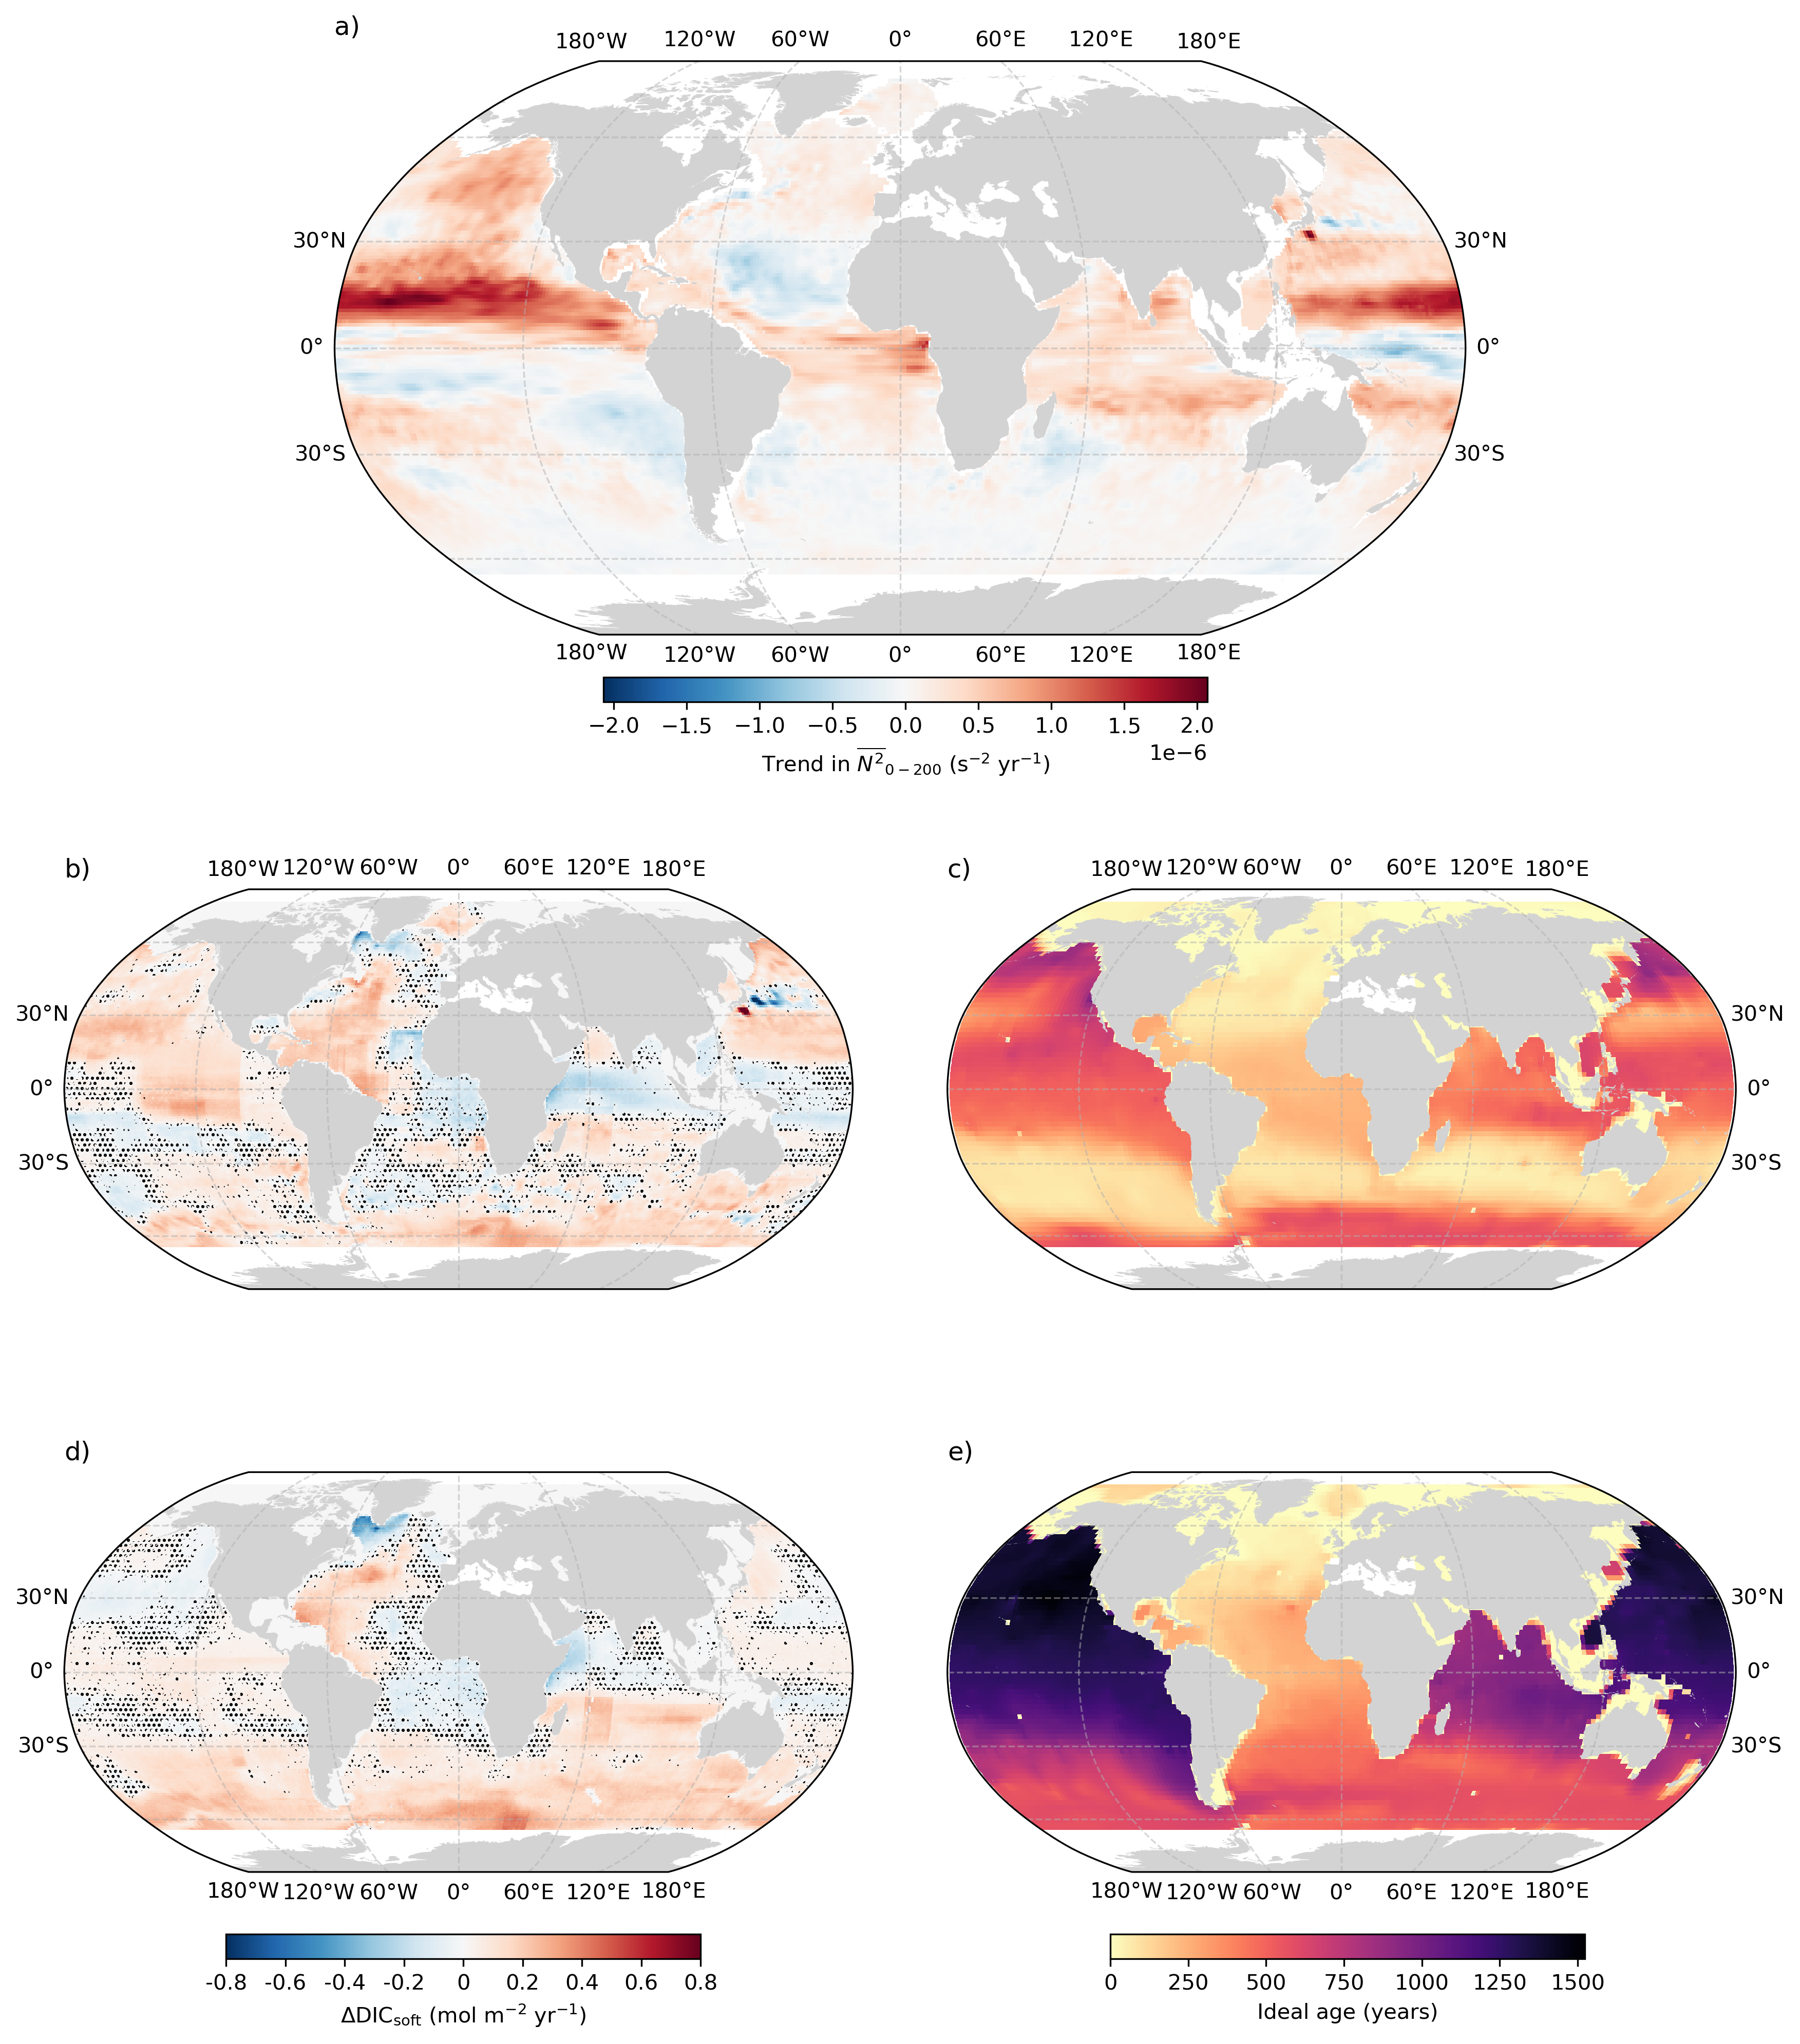

Saved figure to: figs/physics_proxies_5panel_MC_N2_OCIM.png


In [109]:
# ============================================================
# PLOT: 5-panel figure (MC band results + N2 trend + OCIM age)
#
# Uses the MERGED dataset produced by Script 2:
#   data/physics_proxies_merged_with_MC.nc
#
# Panels:
#   a) trend_N2bar_0_200_peryr
#   b) ΔDICsoft (200–1000 m)
#   c) ideal_age_mean_200_1000
#   d) ΔDICsoft (1000–1975 m)
#   e) ideal_age_mean_1000_2000
# ============================================================

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm
import matplotlib.ticker as mticker
import cartopy.mpl.ticker as cticker

# ----------------------------
# Mediterranean mask
# ----------------------------
def mask_mediterranean(lat2d, lon2d):
    lat_min, lat_max = 30, 46
    lon_min, lon_max = -6, 37
    return (
        (lat2d >= lat_min) & (lat2d <= lat_max) &
        (lon2d >= lon_min) & (lon2d <= lon_max)
    )

# ----------------------------
# I/O
# ----------------------------
IN_PATH  = "data/physics_proxies_merged_with_MC.nc"
FIG_PATH = "figs/physics_proxies_5panel_MC_N2_OCIM.png"

# ----------------------------
# Load dataset
# ----------------------------
ds = xr.open_dataset(IN_PATH)

lon = ds["lon"].values
lat = ds["lat"].values
lon2d, lat2d = np.meshgrid(lon, lat)

# ----------------------------
# Fields
# ----------------------------
n2 = ds["trend_N2bar_0_200_peryr"].values

soft_200_1000   = ds["soft_pump_aou_change_200_1000"].values
soft_1000_1975  = ds["soft_pump_aou_change_1000_1975"].values

age_200_1000  = ds["ideal_age_mean_200_1000"].values
age_1000_2000 = ds["ideal_age_mean_1000_2000"].values

# ----------------------------
# Mask Mediterranean Sea
# ----------------------------
med_mask = mask_mediterranean(lat2d, lon2d)

n2 = np.where(med_mask, np.nan, n2)
soft_200_1000  = np.where(med_mask, np.nan, soft_200_1000)
soft_1000_1975 = np.where(med_mask, np.nan, soft_1000_1975)
age_200_1000   = np.where(med_mask, np.nan, age_200_1000)
age_1000_2000  = np.where(med_mask, np.nan, age_1000_2000)

# ----------------------------
# Uncertainty (relative, percentile-based)
# ----------------------------
unc_200_1000  = ds["soft_pump_aou_change_200_1000_uncertainty"].values
unc_1000_1975 = ds["soft_pump_aou_change_1000_1975_uncertainty"].values

# Mask Mediterranean for uncertainty as well
unc_200_1000  = np.where(med_mask, np.nan, unc_200_1000)
unc_1000_1975 = np.where(med_mask, np.nan, unc_1000_1975)

# Relative uncertainty (%)
rel_unc_200_1000 = (unc_200_1000 / np.abs(soft_200_1000)) * 100
rel_unc_1000_1975 = (unc_1000_1975 / np.abs(soft_1000_1975)) * 100

rel_unc_200_1000[np.isnan(rel_unc_200_1000)] = 0
rel_unc_1000_1975[np.isnan(rel_unc_1000_1975)] = 0

# 90th percentile thresholds (same as your reference plot)
thr_200_1000 = np.percentile(rel_unc_200_1000, 90)
thr_1000_1975 = np.percentile(rel_unc_1000_1975, 90)

high_unc_200_1000 = rel_unc_200_1000 > thr_200_1000
high_unc_1000_1975 = rel_unc_1000_1975 > thr_1000_1975


# ----------------------------
# Color norms
# ----------------------------
norm_n2 = TwoSlopeNorm(
    vcenter=0.0,
    vmin=-np.nanmax(np.abs(n2)),
    vmax= np.nanmax(np.abs(n2))
)

# FIXED DICsoft scale (requested)
norm_soft = TwoSlopeNorm(vcenter=0.0, vmin=-0.8, vmax=0.8)

# Age scale (shared)
amin_all = np.nanmin([np.nanmin(age_200_1000), np.nanmin(age_1000_2000)])
amax_all = np.nanmax([np.nanmax(age_200_1000), np.nanmax(age_1000_2000)])

# ----------------------------
# Colorbar positions (figure coords)
# ----------------------------
cbar_pos = {
    "n2":   [0.375, 0.62, 0.28, 0.01],
    "soft": [0.2,   0.11, 0.22, 0.01],
    "age":  [0.61,  0.11, 0.22, 0.01],
}

# ----------------------------
# Layout
# ----------------------------
spacer_height = 0.26
wspace = 0.12

# ----------------------------
# Map styling
# ----------------------------
class CustomLongitudeFormatter(cticker.LongitudeFormatter):
    def __call__(self, lon, pos=None):
        if lon == 0:
            return "0°"
        elif lon < 0:
            return f"{abs(lon):g}°W"
        else:
            return f"{lon:g}°E"

def add_common_map_styling_single_gl(ax):
    ax.set_global()

    land_feature = cfeature.NaturalEarthFeature(
        "physical", "land", "50m",
        edgecolor="none", facecolor="lightgrey"
    )
    ax.add_feature(land_feature)

    gl = ax.gridlines(
        draw_labels=False, alpha=0.5, linestyle="--",
        x_inline=False, y_inline=False
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.xformatter = CustomLongitudeFormatter()
    gl.yformatter = cticker.LatitudeFormatter()

    gl.top_labels = gl.bottom_labels = False
    gl.left_labels = gl.right_labels = False

    ax.figure.canvas.draw()
    for label in gl.xlabel_artists + gl.ylabel_artists:
        label.set_fontsize(8)

    return gl

# ----------------------------
# Figure + GridSpec
# ----------------------------
fig = plt.figure(figsize=(14, 16), dpi=300)

gs = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1.0, spacer_height, 1.0, 1.0],
    hspace=0.02, wspace=wspace
)

# a) N2 (top row)
ax_a = fig.add_subplot(gs[0, :], projection=ccrs.Robinson())
gl_a = add_common_map_styling_single_gl(ax_a)
gl_a.top_labels = gl_a.bottom_labels = True
gl_a.left_labels = gl_a.right_labels = True

im_n2 = ax_a.pcolormesh(
    lon2d, lat2d, n2,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm_n2
)

# b) ΔDICsoft 200–1000
ax_b = fig.add_subplot(gs[2, 0], projection=ccrs.Robinson())
gl_b = add_common_map_styling_single_gl(ax_b)
gl_b.top_labels = gl_b.left_labels = True

im_soft_200 = ax_b.pcolormesh(
    lon2d, lat2d, soft_200_1000,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm_soft
)

ax_b.contourf(
    lon2d, lat2d, high_unc_200_1000,
    levels=[0.5, 1],
    colors="xkcd:grey",
    hatches=["....."],
    alpha=0.001,
    transform=ccrs.PlateCarree()
)


# c) Age 200–1000
ax_c = fig.add_subplot(gs[2, 1], projection=ccrs.Robinson())
gl_c = add_common_map_styling_single_gl(ax_c)
gl_c.top_labels = gl_c.right_labels = True

im_age_200 = ax_c.pcolormesh(
    lon2d, lat2d, age_200_1000,
    transform=ccrs.PlateCarree(),
    cmap="magma_r",
    vmin=amin_all, vmax=amax_all
)

# d) ΔDICsoft 1000–1975
ax_d = fig.add_subplot(gs[3, 0], projection=ccrs.Robinson())
gl_d = add_common_map_styling_single_gl(ax_d)
gl_d.bottom_labels = gl_d.left_labels = True

im_soft_1000 = ax_d.pcolormesh(
    lon2d, lat2d, soft_1000_1975,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm_soft
)

ax_d.contourf(
    lon2d, lat2d, high_unc_1000_1975,
    levels=[0.5, 1],
    colors="xkcd:grey",
    hatches=["....."],
    alpha=0.001,
    transform=ccrs.PlateCarree()
)


# e) Age 1000–2000
ax_e = fig.add_subplot(gs[3, 1], projection=ccrs.Robinson())
gl_e = add_common_map_styling_single_gl(ax_e)
gl_e.bottom_labels = gl_e.right_labels = True

im_age_1000 = ax_e.pcolormesh(
    lon2d, lat2d, age_1000_2000,
    transform=ccrs.PlateCarree(),
    cmap="magma_r",
    vmin=amin_all, vmax=amax_all
)

# ----------------------------
# Panel labels
# ----------------------------
for ax, lab in [(ax_a,"a)"), (ax_b,"b)"), (ax_c,"c)"), (ax_d,"d)"), (ax_e,"e)")]:
    ax.text(
        0.0, 1.08, lab, transform=ax.transAxes,
        fontsize=12, ha="left", va="top",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2)
    )

# ----------------------------
# Colorbars
# ----------------------------
# N2
cax_n2 = fig.add_axes(cbar_pos["n2"])
cb_n2 = fig.colorbar(im_n2, cax=cax_n2, orientation="horizontal")
cb_n2.set_label(r"Trend in $\overline{N^2}_{0-200}$ (s$^{-2}$ yr$^{-1}$)")

# ΔDICsoft
cax_soft = fig.add_axes(cbar_pos["soft"])
cb_soft = fig.colorbar(im_soft_200, cax=cax_soft, orientation="horizontal")

cb_soft.set_label(r"$\Delta$DIC$_{\mathrm{soft}}$ (mol m$^{-2}$ yr$^{-1}$)")

# Set ticks at ±0.2, ±0.4, ±0.6, ±0.8
ticks = [-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8]
cb_soft.set_ticks(ticks)

# Label them as positive magnitudes
cb_soft.set_ticklabels(["-0.8", "-0.6", "-0.4", "-0.2", "0", "0.2", "0.4", "0.6", "0.8"])

# End labels
#cax_soft.text(-0.02, 0.5, "-2", ha="right", va="center",
#              transform=cax_soft.transAxes, fontsize=8)
#cax_soft.text( 1.02, 0.5, "2",  ha="left",  va="center",
#              transform=cax_soft.transAxes, fontsize=8)

# Age
cax_age = fig.add_axes(cbar_pos["age"])
cb_age = fig.colorbar(im_age_200, cax=cax_age, orientation="horizontal")
cb_age.set_label("Ideal age (years)")

# ----------------------------
# Save
# ----------------------------
os.makedirs("figs", exist_ok=True)
fig.savefig(FIG_PATH, bbox_inches="tight", dpi=300)
plt.show()

print(f"Saved figure to: {FIG_PATH}")
